# Shears — the loss across bases

Supports Supplementary Note 3 (One sweep as the model). `s03b` fits the disharmonic fold of `s03a`
on one basis. Here the same data, settings and training are fitted on `N_SEEDS` draws of the
random Fourier basis, each with **one sweep** and with **RK4** (`N_RK4` steps), so that the two
differ only in the map. Only the loss is kept: the question is where each levels off, not what
any one fit looks like. The first seed is the basis of `s03b`.

As everywhere, `best=True`: each fit ends on its lowest-loss state, and the last entry of each
curve is the loss of that state, not of the last iteration.

Writes `results/shears_ensemble.npz`, read by `s03d_shears_figures`. Runs in `curlew_dev`.

## Setup

In [1]:
from pathlib import Path
from time import perf_counter

import numpy as np
import matplotlib.pyplot as plt
import torch

import curlew
from curlew.core import CSet, HSet
from curlew.geology import restore
from curlew.kinematics.euler import euler_velocity

curlew.device = "cpu"
curlew.dtype = torch.float32
curlew.default_dim = 2

RES_DIR = Path("./results")
RES_DIR.mkdir(parents=True, exist_ok=True)

d = np.load("data/disharmonic_fold.npz")
horizons, gp, gv = list(d["horizons"]), d["gp"], d["gv"]
C = CSet(gp=gp, gv=gv, eq=horizons)

## The fits

The settings of `s03b`; keep the two in step. About two minutes per basis.

In [2]:
FOURIER_SEED = 404                # the first basis, the one of s03b
N_SEEDS = 15
BAND = (1000.0, 4000.0)           # wavelength band (m)
N_FEATURES, N_DIRECTIONS = 128, 32
N_RK4 = 10                        # RK4 steps of the RK4 fits
EPOCHS = 2500
LOG_EVERY = 10                    # loss recorded every LOG_EVERY iterations
LR_ADAM = 5e-2                   # Adam rate for the phases and biases
LR_SGD, AMP_MOMENTUM = 5e-2, 0.9  # gradient descent with momentum for the amplitudes
WEIGHTS = dict(grad_loss="1.", eq_loss="1.")   # bedding and equal-elevation loss weights

seed_rng = np.random.default_rng(FOURIER_SEED + 91)
SEEDS = [FOURIER_SEED]
while len(SEEDS) < N_SEEDS:
    candidate = int(seed_rng.integers(0, 2**31 - 1))
    if candidate not in SEEDS:
        SEEDS.append(candidate)


def fit(name, integrator, n_steps, seed):
    torch.manual_seed(405)
    velocity = euler_velocity(2, n_features=N_FEATURES, n_directions=N_DIRECTIONS, seed=int(seed),
                              length_scale_range=BAND, stream="alpha", activation="cubic",
                              energy_normalised=True)
    event = restore(
        f"s03_{name}", C=C, H=HSet().zero(**WEIGHTS), velocity=velocity,
        n_steps=n_steps, integrator=integrator, depth_axis=1, init_std=0.0, sigma_floor=0.0,
        signed_normals=True, learning_rate=LR_ADAM, pin=torch.zeros(2),
        optimizer={"amplitude": (torch.optim.SGD, dict(lr=LR_SGD, momentum=AMP_MOMENTUM)),
                   "shape": (torch.optim.Adam, dict(lr=LR_ADAM))},
    )
    for k, h in enumerate(horizons):
        event.addIsosurface(f"H{k}", seed=h)
    model = curlew.GeoModel([event])
    loss = []

    def record(epoch, epochs):                     # the loss every LOG_EVERY iterations
        if epoch % LOG_EVERY == 0:
            with torch.no_grad():
                loss.append(float(event.loss().total()))

    t0 = perf_counter()
    model.prefit(epochs=EPOCHS, vb=True, early_stop=None, best=True, schedule=record)
    seconds = perf_counter() - t0
    with torch.no_grad():
        loss.append(float(event.loss().total()))   # the reloaded, lowest-loss state
    print(f"seed {seed}, {name}: {seconds:.0f} s, final loss {loss[-1]:.3g}, last iteration {loss[-2]:.3g}")
    return np.array(loss), seconds


iteration = np.r_[np.arange(0, EPOCHS, LOG_EVERY), EPOCHS]
curves = {"sweep": [], "rk4": []}
seconds = {"sweep": [], "rk4": []}
for seed in SEEDS:
    for name, integrator, n_steps in (("sweep", "shear", 0), ("rk4", "rk4", N_RK4)):
        loss, t = fit(name, integrator, n_steps, seed)
        curves[name].append(loss)
        seconds[name].append(t)
curves = {k: np.array(v) for k, v in curves.items()}
seconds = {k: np.array(v) for k, v in seconds.items()}

L=0.001 grad_loss=0.000 eq_loss=0.000: : 2500/2500|


seed 404, sweep: 17 s, final loss 0.000331, last iteration 0.00039


L=0.015 grad_loss=0.004 eq_loss=0.011: : 2500/2500|


seed 404, rk4: 74 s, final loss 0.0133, last iteration 0.0138


L=0.001 grad_loss=0.000 eq_loss=0.001: : 2500/2500|


seed 35034316, sweep: 17 s, final loss 0.0012, last iteration 0.00142


... (50 outputs left out)

L=0.001 grad_loss=0.000 eq_loss=0.001: : 2500/2500|


seed 16222087, sweep: 21 s, final loss 0.000941, last iteration 0.00126


L=0.022 grad_loss=0.002 eq_loss=0.020: : 2500/2500|


seed 16222087, rk4: 89 s, final loss 0.0126, last iteration 0.0224


### Quick look

Every basis (thin) and the median (thick). Not saved.

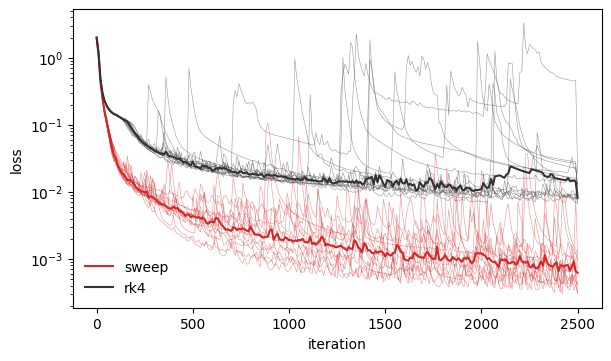

In [3]:
fig, ax = plt.subplots(figsize=(6, 3.5), constrained_layout=True)
for name, color in (("sweep", "C3"), ("rk4", "0.2")):
    ax.semilogy(iteration, curves[name].T, color=color, lw=0.4, alpha=0.5)
    ax.semilogy(iteration, np.nanmedian(curves[name], axis=0), color=color, lw=1.5, label=name)
ax.set_xlabel("iteration")
ax.set_ylabel("loss")
ax.legend(frameon=False)
plt.show()

## Numbers quoted in Supplementary Note 3

Per basis: the final loss, the loss half way through training, and the iteration at which the
sweep first passes the final loss of RK4 on the same basis. A fit counts as diverged if its final
loss is not finite.

In [4]:
half = len(iteration) // 2
final = {k: v[:, -1] for k, v in curves.items()}
for name in curves:
    ok = np.isfinite(final[name])
    print(f"{name}: final loss median {np.median(final[name][ok]):.2g} "
          f"(5-95% {np.percentile(final[name][ok], 5):.2g}-{np.percentile(final[name][ok], 95):.2g}), "
          f"half way {np.nanmedian(curves[name][:, half]):.2g}, second half falls by "
          f"{np.nanmedian(curves[name][:, half] / final[name]):.2f}x, "
          f"{np.median(seconds[name]):.0f} s, diverged {int((~ok).sum())} of {len(ok)}")
both = np.isfinite(final["sweep"]) & np.isfinite(final["rk4"])
ratio = final["rk4"][both] / final["sweep"][both]
print(f"RK4 / sweep final loss: median {np.median(ratio):.1f} (range {ratio.min():.1f}-{ratio.max():.1f}), "
      f"sweep lower on {int((ratio > 1).sum())} of {both.sum()}")
passes = [iteration[np.argmax(s < f)] for s, f, b in zip(curves["sweep"], final["rk4"], both)
          if b and (s < f).any()]
print(f"sweep passes the final RK4 loss at iteration: median {np.median(passes):.0f}, "
      f"range {min(passes)}-{max(passes)}")

sweep: final loss median 0.00062 (5-95% 0.00031-0.0011), half way 0.0015, second half falls by 2.65x, 20 s, diverged 0 of 15
rk4: final loss median 0.0082 (5-95% 0.0068-0.015), half way 0.014, second half falls by 1.68x, 87 s, diverged 0 of 15
RK4 / sweep final loss: median 13.4 (range 7.1-60.0), sweep lower on 15 of 15
sweep passes the final RK4 loss at iteration: median 280, range 140-430


## Save

In [5]:
np.savez(RES_DIR / "shears_ensemble.npz", seeds=np.array(SEEDS), iteration=iteration, band=np.array(BAND), n_rk4=N_RK4,
         **{f"{k}_loss": v for k, v in curves.items()}, **{f"{k}_seconds": v for k, v in seconds.items()})
print("wrote", RES_DIR / "shears_ensemble.npz")

wrote results/shears_ensemble.npz
